# k-NN V4

For this experiment, I wanted to see if normalizing the features would improve the accuracy. I compared the original features with the standardized ones, while keeping the same k and distance function as before.

First, I imported the libraries and functions I'll need.

In [1]:
from pathlib import Path
from time import perf_counter
import sys

import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.data_loader import load_task, split_train_val, standardize
from src.models.knn import KNNClassifier, euclidean_distance

image_k = 1
sentiment_k = 3


I started by comparing both versions on the image dataset.

In [2]:
X, y, image_X_test, image_test_ids = load_task("image")
X_train, X_val, y_train, y_val = split_train_val(
    X, y, val_fraction=0.2, seed=42
)
image_X_train = X_train[:1000]
image_y_train = y_train[:1000]
image_X_val = X_val[:200]
image_y_val = y_val[:200]

# Use only the selected training rows to calculate the scaling statistics.
image_X_train_std, image_X_val_std = standardize(
    image_X_train, image_X_val
)
configurations = [
    (False, image_X_train, image_X_val),
    (True, image_X_train_std, image_X_val_std),
]
result_dir = project_root / "results" / "image"
v3_validation = pd.read_csv(result_dir / "knn_v3_validation.csv")
v3_summary = pd.read_csv(result_dir / "knn_v3_summary.csv")
assert v3_validation["validation_index"].tolist() == list(range(200))
assert v3_validation["actual_label"].tolist() == image_y_val.tolist()

image_rows = []
image_validation_predictions = {}
image_best_accuracy = -1
print("Image: k=" + str(image_k) + ", 1000 training samples, 200 validation samples")
for normalized, train_features, validation_features in configurations:
    clf = KNNClassifier(k=image_k, distance_fn=euclidean_distance)
    clf.fit(train_features, image_y_train)
    start = perf_counter()
    y_pred = clf.predict(validation_features)
    prediction_time = perf_counter() - start
    accuracy = sum(p == t for p, t in zip(y_pred, image_y_val)) / len(image_y_val)
    image_validation_predictions[normalized] = y_pred
    image_rows.append({
        "dataset": "image",
        "version": "V4",
        "k": image_k,
        "distance_metric": "euclidean",
        "voting_method": "majority",
        "normalized": normalized,
        "training_samples": len(train_features),
        "validation_samples": len(validation_features),
        "validation_accuracy": accuracy,
        "prediction_time_seconds": prediction_time,
    })
    name = "Standardized features" if normalized else "Original features"
    print(f"{name:22s}  accuracy={accuracy:.2%}  prediction time={prediction_time:.6f} s")

    # Original features come first, so they win an accuracy tie.
    if accuracy > image_best_accuracy:
        image_best_normalized = normalized
        image_best_accuracy = accuracy
    if not normalized:
        assert accuracy == 0.215
        assert accuracy == v3_summary.loc[v3_summary["distance_metric"] == "Euclidean", "validation_accuracy"].iloc[0]
        assert y_pred == v3_validation["predicted_label"].tolist()

image_summary = pd.DataFrame(image_rows)
image_summary.to_csv(result_dir / "knn_v4_summary.csv", index=False)
pd.DataFrame({
    "validation_index": range(len(image_y_val)),
    "actual_label": image_y_val,
    "predicted_label": image_validation_predictions[image_best_normalized],
}).to_csv(result_dir / "knn_v4_validation.csv", index=False)
image_best_name = "Standardized features" if image_best_normalized else "Original features"
print(f"Selected: {image_best_name}, accuracy={image_best_accuracy:.2%}")


Image: k=1, 1000 training samples, 200 validation samples
Original features       accuracy=21.50%  prediction time=0.931741 s
Standardized features   accuracy=17.00%  prediction time=1.325589 s
Selected: Original features, accuracy=21.50%


Then I repeated the same experiment with the sentiment dataset.

In [3]:
X, y, sentiment_X_test, sentiment_test_ids = load_task("sentiment")
X_train, X_val, y_train, y_val = split_train_val(
    X, y, val_fraction=0.2, seed=42
)
sentiment_X_train = X_train[:1000]
sentiment_y_train = y_train[:1000]
sentiment_X_val = X_val[:200]
sentiment_y_val = y_val[:200]

# Use only the selected training rows to calculate the scaling statistics.
sentiment_X_train_std, sentiment_X_val_std = standardize(
    sentiment_X_train, sentiment_X_val
)
configurations = [
    (False, sentiment_X_train, sentiment_X_val),
    (True, sentiment_X_train_std, sentiment_X_val_std),
]
result_dir = project_root / "results" / "sentiment"
v3_validation = pd.read_csv(result_dir / "knn_v3_validation.csv")
v3_summary = pd.read_csv(result_dir / "knn_v3_summary.csv")
assert v3_validation["validation_index"].tolist() == list(range(200))
assert v3_validation["actual_label"].tolist() == sentiment_y_val.tolist()

sentiment_rows = []
sentiment_validation_predictions = {}
sentiment_best_accuracy = -1
print("Sentiment: k=" + str(sentiment_k) + ", 1000 training samples, 200 validation samples")
for normalized, train_features, validation_features in configurations:
    clf = KNNClassifier(k=sentiment_k, distance_fn=euclidean_distance)
    clf.fit(train_features, sentiment_y_train)
    start = perf_counter()
    y_pred = clf.predict(validation_features)
    prediction_time = perf_counter() - start
    accuracy = sum(p == t for p, t in zip(y_pred, sentiment_y_val)) / len(sentiment_y_val)
    sentiment_validation_predictions[normalized] = y_pred
    sentiment_rows.append({
        "dataset": "sentiment",
        "version": "V4",
        "k": sentiment_k,
        "distance_metric": "euclidean",
        "voting_method": "majority",
        "normalized": normalized,
        "training_samples": len(train_features),
        "validation_samples": len(validation_features),
        "validation_accuracy": accuracy,
        "prediction_time_seconds": prediction_time,
    })
    name = "Standardized features" if normalized else "Original features"
    print(f"{name:22s}  accuracy={accuracy:.2%}  prediction time={prediction_time:.6f} s")

    # Original features come first, so they win an accuracy tie.
    if accuracy > sentiment_best_accuracy:
        sentiment_best_normalized = normalized
        sentiment_best_accuracy = accuracy
    if not normalized:
        assert accuracy == 0.575
        assert accuracy == v3_summary.loc[v3_summary["distance_metric"] == "Euclidean", "validation_accuracy"].iloc[0]
        assert y_pred == v3_validation["predicted_label"].tolist()

sentiment_summary = pd.DataFrame(sentiment_rows)
sentiment_summary.to_csv(result_dir / "knn_v4_summary.csv", index=False)
pd.DataFrame({
    "validation_index": range(len(sentiment_y_val)),
    "actual_label": sentiment_y_val,
    "predicted_label": sentiment_validation_predictions[sentiment_best_normalized],
}).to_csv(result_dir / "knn_v4_validation.csv", index=False)
sentiment_best_name = "Standardized features" if sentiment_best_normalized else "Original features"
print(f"Selected: {sentiment_best_name}, accuracy={sentiment_best_accuracy:.2%}")


Sentiment: k=3, 1000 training samples, 200 validation samples
Original features       accuracy=57.50%  prediction time=1.217574 s
Standardized features   accuracy=57.00%  prediction time=1.179922 s
Selected: Original features, accuracy=57.50%


I plotted the accuracies to compare the results.

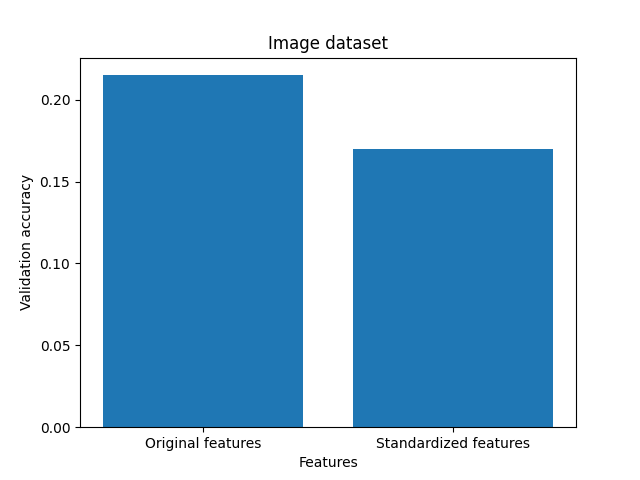

In [4]:
knn_result_dir = project_root / "results" / "knn"
knn_result_dir.mkdir(parents=True, exist_ok=True)
plt.figure()
plt.bar(["Original features", "Standardized features"], image_summary["validation_accuracy"])
plt.xlabel("Features")
plt.ylabel("Validation accuracy")
plt.title("Image dataset")
plt.savefig(knn_result_dir / "knn_v4_image_accuracy.png")
plt.show()


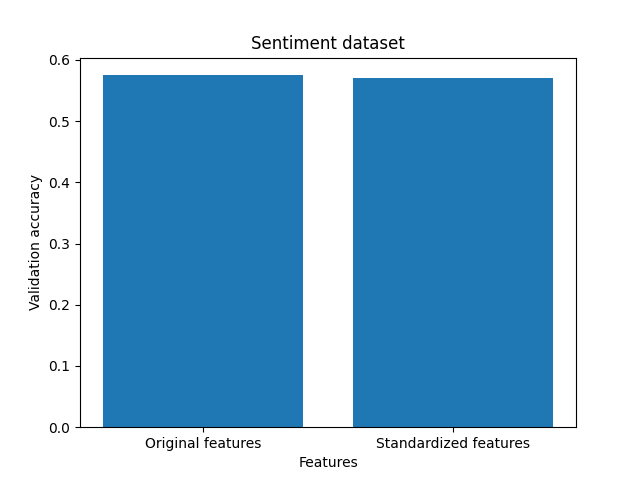

In [5]:
knn_result_dir = project_root / "results" / "knn"
knn_result_dir.mkdir(parents=True, exist_ok=True)
plt.figure()
plt.bar(["Original features", "Standardized features"], sentiment_summary["validation_accuracy"])
plt.xlabel("Features")
plt.ylabel("Validation accuracy")
plt.title("Sentiment dataset")
plt.savefig(knn_result_dir / "knn_v4_sentiment_accuracy.png")
plt.show()


Finally, I checked whether normalization improved the accuracy for either dataset.

In [6]:
for dataset, summary, selected in [
    ("Image", image_summary, image_best_name),
    ("Sentiment", sentiment_summary, sentiment_best_name),
]:
    original_accuracy = summary.loc[0, "validation_accuracy"]
    standardized_accuracy = summary.loc[1, "validation_accuracy"]
    print(f"{dataset}: original={original_accuracy:.2%}, standardized={standardized_accuracy:.2%}")
    print(f"Normalization improved accuracy: {standardized_accuracy > original_accuracy}. Selected: {selected}")


Image: original=21.50%, standardized=17.00%
Normalization improved accuracy: False. Selected: Original features
Sentiment: original=57.50%, standardized=57.00%
Normalization improved accuracy: False. Selected: Original features


I used the best version for each dataset to predict the test labels.

In [7]:
if image_best_normalized:
    image_submission_train, _, image_submission_test = standardize(
        image_X_train, image_X_val, image_X_test
    )
else:
    image_submission_train = image_X_train
    image_submission_test = image_X_test

image_clf = KNNClassifier(k=image_k, distance_fn=euclidean_distance)
image_clf.fit(image_submission_train, image_y_train)
start = perf_counter()
image_test_predictions = image_clf.predict(image_submission_test)
print(f"Image: predicted {len(image_test_predictions)} test labels in {perf_counter() - start:.2f} s")


Image: predicted 5000 test labels in 33.37 s


In [8]:
if sentiment_best_normalized:
    sentiment_submission_train, _, sentiment_submission_test = standardize(
        sentiment_X_train, sentiment_X_val, sentiment_X_test
    )
else:
    sentiment_submission_train = sentiment_X_train
    sentiment_submission_test = sentiment_X_test

sentiment_clf = KNNClassifier(k=sentiment_k, distance_fn=euclidean_distance)
sentiment_clf.fit(sentiment_submission_train, sentiment_y_train)
start = perf_counter()
sentiment_test_predictions = sentiment_clf.predict(sentiment_submission_test)
print(f"Sentiment: predicted {len(sentiment_test_predictions)} test labels in {perf_counter() - start:.2f} s")


Sentiment: predicted 5000 test labels in 41.04 s


In [9]:
image_predictions = pd.DataFrame({"id": image_test_ids, "label": image_test_predictions})
sentiment_predictions = pd.DataFrame({"id": sentiment_test_ids, "label": sentiment_test_predictions})
assert len(image_predictions) == 5000 and len(sentiment_predictions) == 5000
assert image_predictions["label"].between(0, 49).all()
assert sentiment_predictions["label"].between(0, 2).all()

predictions = pd.concat([image_predictions, sentiment_predictions], ignore_index=True)
sample_submission = pd.read_csv(project_root / "data" / "raw" / "sample_submission.csv")
assert len(predictions) == 10000 and len(sample_submission) == 10000
assert predictions["id"].is_unique and sample_submission["id"].is_unique
assert set(predictions["id"]) == set(sample_submission["id"])

# A left merge keeps the sample submission's ID order.
submission = sample_submission[["id"]].merge(predictions, on="id", how="left", sort=False)
assert submission.columns.tolist() == ["id", "label"]
assert submission["id"].tolist() == sample_submission["id"].tolist()
assert not submission.isna().any().any()
assert pd.api.types.is_integer_dtype(submission["label"])

submission_dir = project_root / "submission" / "knn"
submission_dir.mkdir(parents=True, exist_ok=True)
submission_path = submission_dir / "submission_v4_knn.csv"
submission.to_csv(submission_path, index=False)
saved_submission = pd.read_csv(submission_path)
assert pd.api.types.is_integer_dtype(saved_submission["label"])
pd.testing.assert_frame_equal(saved_submission, submission, check_dtype=False)
print("Saved and checked 10000 predictions in", submission_path)

v2_submission = pd.read_csv(submission_dir / "submission_v2_knn.csv")
assert saved_submission["id"].tolist() == v2_submission["id"].tolist()
changed_predictions = int((saved_submission["label"] != v2_submission["label"]).sum())
print(f"Identical predictions to V2: {changed_predictions == 0}")
print(f"Changed predictions compared with V2: {changed_predictions}")
if not image_best_normalized and not sentiment_best_normalized:
    pd.testing.assert_frame_equal(saved_submission, v2_submission, check_dtype=False)


Saved and checked 10000 predictions in C:\Users\user\OneDrive\Documentos\Fall2026\COMP472\team_project\COMP472\submission\knn\submission_v4_knn.csv
Identical predictions to V2: True
Changed predictions compared with V2: 0


In [10]:
tracker_path = knn_result_dir / "kaggle_scores.csv"
tracker = pd.read_csv(tracker_path, dtype=str, keep_default_na=False)
assert tracker["version"].is_unique
v4_row = {
    "version": "V4",
    "image_validation_accuracy": image_best_accuracy,
    "sentiment_validation_accuracy": sentiment_best_accuracy,
    "kaggle_public_score": "",
    "submitted_to_kaggle": False,
    "submission_filename": submission_path.name,
    "notes": f"Compared original and standardized features; image: {image_best_name}; sentiment: {sentiment_best_name}.",
}
matching = tracker["version"] == "V4"
if matching.any():
    # Preserve any recorded Kaggle score and status on reruns.
    for column in ("image_validation_accuracy", "sentiment_validation_accuracy", "submission_filename", "notes"):
        tracker.loc[matching, column] = v4_row[column]
else:
    tracker = pd.concat([tracker, pd.DataFrame([v4_row])], ignore_index=True)
assert tracker["version"].is_unique
tracker.to_csv(tracker_path, index=False)
print(tracker.to_string(index=False))


version image_validation_accuracy sentiment_validation_accuracy kaggle_public_score submitted_to_kaggle   submission_filename                                                                                                notes
     V1                      0.21                         0.575                                   False                                                                                k=3 and 1,000 training samples per dataset.
     V2                     0.215                         0.575               0.329                True submission_v2_knn.csv                                             Tested k=1, 3, 5, 10, 20; best image k=1, sentiment k=3.
     V3                     0.215                         0.575                                   False submission_v3_knn.csv      Compared Euclidean, Manhattan, Minkowski p=3; best image: Euclidean; best sentiment: Euclidean.
     V4                     0.215                         0.575                             